# GetModel: giant-planet models, synthetic data and posterior bands

**This Jupyter notebook was created with the assistance of CODEX. Its purpose is to demonstrate how to work with Exo-Striker synthetic models, generate synthetic observations, add noise, plot model predictions and data, and propagate posterior samples into model uncertainty bands.**

Two planets of **1.0 and 1.1 Jupiter masses**, with **320 and 680 day** periods, orbit a solar-mass star. We test Keplerian/N-body RVs, transit flux, TTVs, depths/durations, standard + planetary astrometry, irregular BJD, Gaussian measurement noise and timestamp jitter. A bundled **real fitted `.ses` session** supplies retained MCMC and weighted nested-sampling samples for grey 1/2/3σ model bands.

Run all cells from the repository root or `examples/`. Select a Python environment with the Exo-Striker dependencies, Jupyter and Matplotlib. First use may compile the Fortran models. Output CSVs/figures go to `examples/results/GetModel_demo/`; the included `.ses` is read without overwriting it. Default execution does **not** launch new samplers.

This is synthetic tutorial data, not an observed planetary system. Planet radii, edge-on inclinations, stellar properties and astrometric standard solution are stated assumptions. MCMC/NS runs are illustrative; assess mixing, effective tail samples and convergence before interpreting 3σ regions scientifically.

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'exostriker').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'exostriker').is_dir():
    raise RuntimeError('Run this notebook from the repository root or examples/.')
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'examples'))
OUTPUT = ROOT / 'examples' / 'results' / 'GetModel_demo'
OUTPUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(OUTPUT / 'matplotlib_cache'))

from copy import deepcopy
from dataclasses import replace
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt
from IPython.display import display
from exostriker.lib.model_only import GetModel, GetModelDefaults
from exostriker.lib.model_posterior import (
    GetModelFromSession, GetPosteriorModels, GetModelEnsemble,
    PosteriorSamplesFromSession, SessionModelAdapter,
)
from model_simulation_tools import (
    EPOCH, SPAN, STANDARD, giant_planets, earth_observer, plot_band, load_demo_session, write_csv,
)

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2, 'text.usetex': False})
SEED = 42
rng = np.random.default_rng(SEED)
print('Epoch:', EPOCH, 'BJD; baseline:', SPAN, 'days')
print('Files:', OUTPUT)

Epoch: 2459000.0 BJD; baseline: 3200.0 days
Files: /home/trifonov/exostriker_codex/examples/results/GetModel_demo


## 1. Named planet dictionaries and switches

`K` is m/s, `P` is days, all orbital angles are degrees, and `M0` refers to `EPOCH`. `giant_planets()` derives K from the specified physical masses using the RVmod Jacobi convention. The nearly edge-on inclinations make transits possible; these are not generic randomly oriented giant planets.

Only RV defaults to enabled. Use `GetModelDefaults()` for fresh dictionaries, or concise booleans such as `models={'RV': False, 'TTV': True}`.

In [2]:
planets = giant_planets()
display(Table(rows=[{'planet': name, **parameters} for name, parameters in planets.items()]))
print('Injected masses [Mjup]: b=1.0, c=1.1')
print('Defaults:', {name: settings['enabled'] for name, settings in GetModelDefaults().items()})

one_epoch = GetModel(planets, BJD=EPOCH, epoch=EPOCH)
assert one_epoch.RV.BJD.shape == (1,)
assert one_epoch.Transit is None and one_epoch.TTV == {} and one_epoch.Astrometry is None
print('Single-epoch RV:', one_epoch.RV.model[0], 'm/s')

planet,K,P,e,omega,M0,inclination,node,radius_ratio
str1,float64,float64,float64,float64,float64,float64,float64,float64
b,29.79060649378471,320.0,0.08,40.0,20.0,89.98,0.0,0.10045
c,25.574329524304357,680.0,0.12,110.0,300.0,89.98,0.0,0.10045


Injected masses [Mjup]: b=1.0, c=1.1
Defaults: {'RV': True, 'Transit': False, 'TTV': False, 'Astrometry': False}


Single-epoch RV: 34.44944285236231 m/s


## 2. Keplerian versus N-body RV models and per-planet contributions

The same osculating parameters at the same epoch initialize both models. Their later differences are dynamical interactions. `points` determines plotting density; `step` and `tolerance` control numerical integration independently.

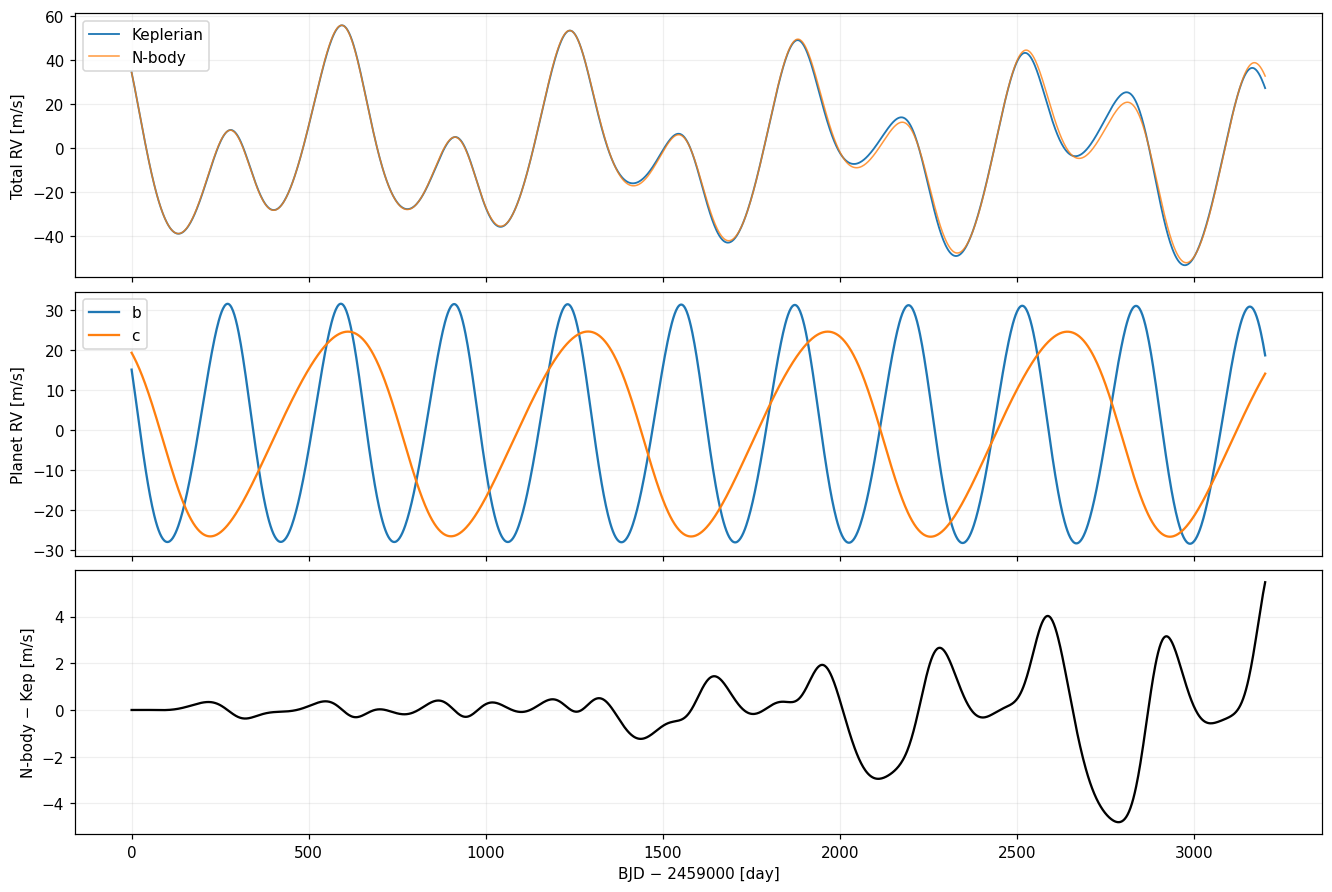

In [3]:
dense_times = np.linspace(EPOCH, EPOCH + SPAN, 1600)
kepler = GetModel(planets, BJD=dense_times, epoch=EPOCH, model='keplerian')
nbody = GetModel(planets, BJD=dense_times, epoch=EPOCH, model='nbody', step=3., tolerance=1e-12)

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(12, 8), layout='constrained')
axes[0].plot(dense_times-EPOCH, kepler.RV.model, label='Keplerian', lw=1.2)
axes[0].plot(dense_times-EPOCH, nbody.RV.model, label='N-body', lw=1., alpha=.8)
axes[0].set_ylabel('Total RV [m/s]')
axes[0].legend()
for name, values in nbody.RV.components.items():
    axes[1].plot(dense_times-EPOCH, values, label=name)
axes[1].set_ylabel('Planet RV [m/s]')
axes[1].legend()
axes[2].plot(dense_times-EPOCH, nbody.RV.model-kepler.RV.model, color='black')
axes[2].set(xlabel=f'BJD − {EPOCH:.0f} [day]', ylabel='N-body − Kep [m/s]')
fig.savefig(OUTPUT/'RV_dynamics.png', dpi=160)
plt.show()

## 3. Irregular observations, heteroscedastic noise and timestamp jitter

Here `time_jitter.sigma=0.15` days scatters an irregular observing schedule. RV is evaluated at the actual shifted BJD. `noise.sigma` then adds independent measurement noise in m/s. `model` remains noiseless, `data` contains simulated measurements, and `uncertainty` retains their supplied errors. Neither setting changes NumPy's global random generator.

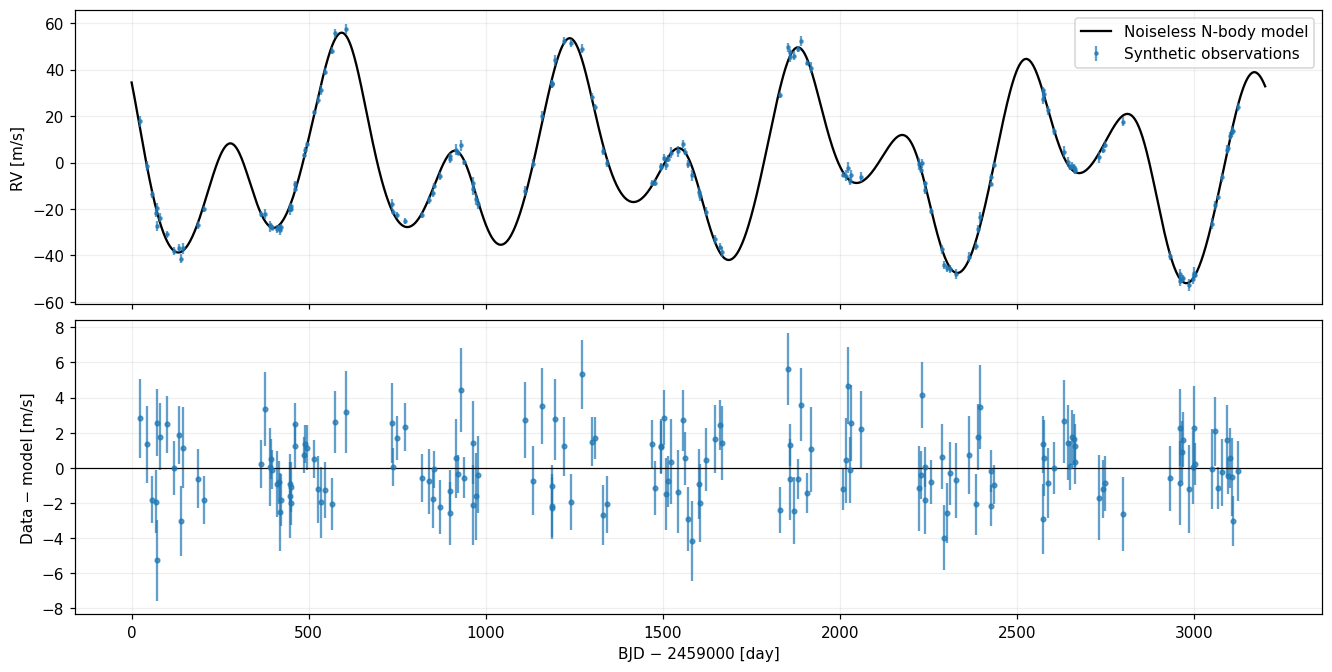

Timestamp scatter rms [day]: 0.14302795411194688


In [4]:
requested_rv = EPOCH + np.sort(rng.uniform(0., SPAN, 240))
season = ((requested_rv-EPOCH) % 365.25) < 250.
requested_rv = requested_rv[season]
rv_sigma = rng.uniform(1., 2.5, len(requested_rv))
rv_config = {'RV': {'BJD': requested_rv,
                    'noise': {'sigma': rv_sigma},
                    'time_jitter': {'sigma': .15}}}
rv_data = GetModel(planets, epoch=EPOCH, model='nbody', models=rv_config, seed=SEED)
repeat = GetModel(planets, epoch=EPOCH, model='nbody', models=rv_config, seed=SEED)
np.testing.assert_array_equal(rv_data.RV.data, repeat.RV.data)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 6), layout='constrained')
axes[0].plot(dense_times-EPOCH, nbody.RV.model, color='black', label='Noiseless N-body model')
axes[0].errorbar(rv_data.RV.BJD-EPOCH, rv_data.RV.data, yerr=rv_data.RV.uncertainty,
                 fmt='.', ms=4, alpha=.7, label='Synthetic observations')
axes[0].set_ylabel('RV [m/s]')
axes[0].legend()
axes[1].errorbar(rv_data.RV.BJD-EPOCH, rv_data.RV.data-rv_data.RV.model,
                 yerr=rv_data.RV.uncertainty, fmt='.', alpha=.7)
axes[1].axhline(0., color='black', lw=.8)
axes[1].set(xlabel=f'BJD − {EPOCH:.0f} [day]', ylabel='Data − model [m/s]')
plt.show()
print('Timestamp scatter rms [day]:', np.std(rv_data.RV.BJD-rv_data.RV.requested_BJD))

## 4. Transit events, synthetic timing data, depths and durations

TTV is independent of the flux switch and the plotting grid. Event tables contain **actual foreground disk crossings**, not all conjunctions. N_transit starts at 1 for each planet. `BJD_minus_mean` is centered event time; `O_C` is a different quantity, referenced to the first returned event and initial period. Timing noise is in days, so seconds must be divided by 86400.

Transit depths/durations remain physical model predictions; simulated `data` in a TTV table represents measured midpoint BJD only.

planet,N_transit,BJD,BJD_minus_mean,O_C_seconds,Depth,T14_hours
str1,int64,float64,float64,float64,float64,float64
b,1,2459020.664632325,-1442.0739885027344,0.0,0.012085637620378065,12.931634317194948
b,2,2459340.277714654,-1122.4609061738793,-33429.6867869034,0.0120855673548933,12.968770276861505
b,3,2459660.335789667,-802.4028311606996,-28412.005648183185,0.012085500651411119,13.012152302764662
b,4,2459980.671130206,-482.06749062214885,561.4168826043169,0.012085429212045806,13.044079608287575
b,5,2460301.331167171,-161.40745365718044,57588.61065586534,0.012085366713384782,13.081782382172605


planet,N_transit,BJD,BJD_minus_mean,O_C_seconds,Depth,T14_hours
str1,int64,float64,float64,float64,float64,float64
c,1,2459083.66520249,-1356.0590578336876,0.0,0.012071035057375612,15.587709147998908
c,2,2459763.0617504697,-676.6625098539967,-52138.25455470433,0.01207112072578409,15.5910950641628
c,3,2460440.8931248337,1.168864510033245,-239507.50950252113,0.012071171143479664,15.602797213879967
c,4,2461117.492843719,677.7685833953904,-533291.7978076672,0.012071234705618772,15.595183496308891
c,5,2461793.5083801057,1353.7841197822602,-877549.4539821142,0.012071316987257608,15.563647825460066


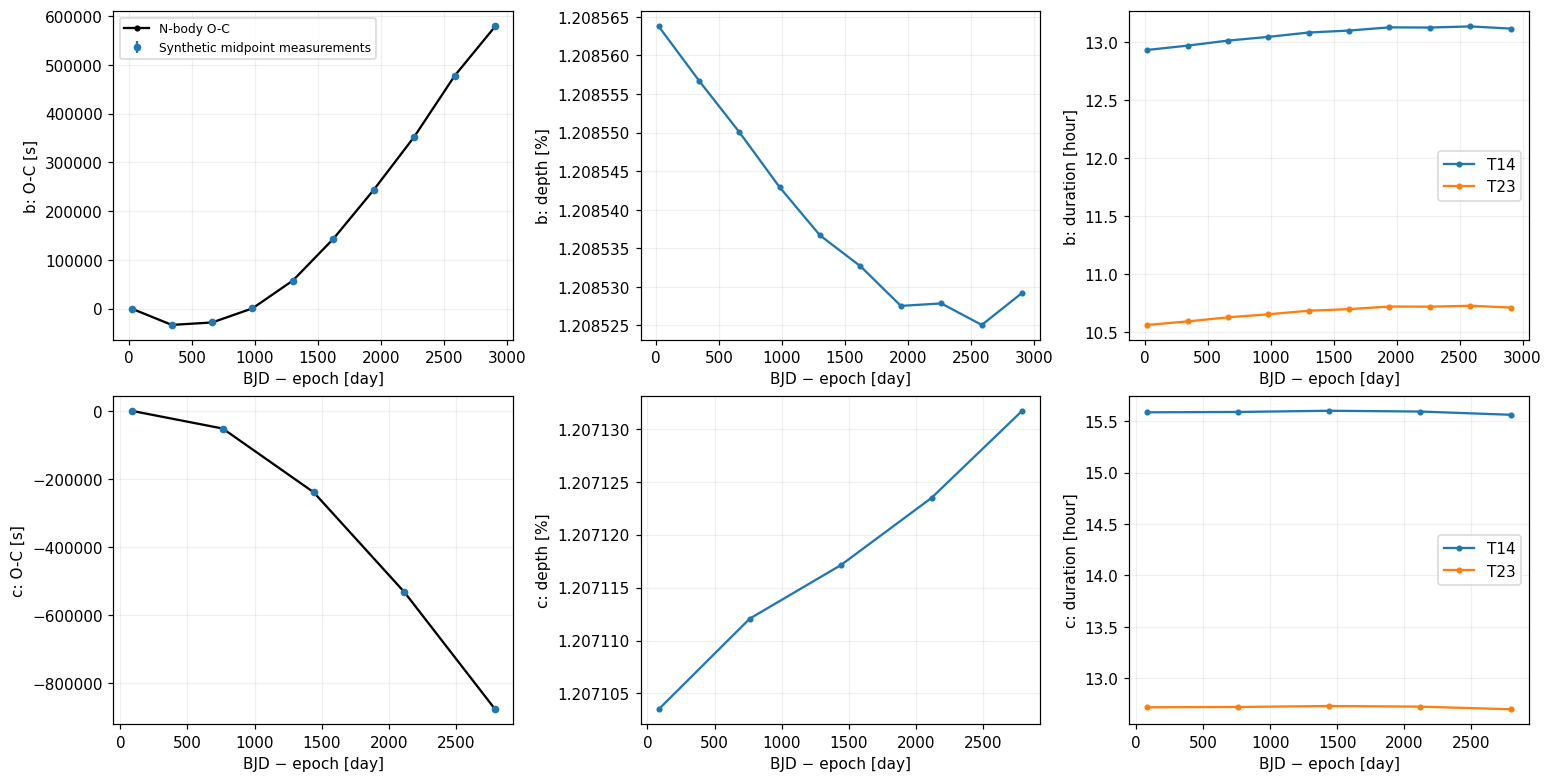

In [5]:
event_config = {
    'RV': False,
    'TTV': {'enabled': True, 'start': EPOCH, 'end': EPOCH+SPAN,
            'noise': {'sigma': {'b': 60./86400., 'c': 90./86400.}}},
    'Transit': {'enabled': False, 'parameters': {'limb_dark': 'quadratic', 'coefficients': [.4, .2]}},
}
events = GetModel(planets, epoch=EPOCH, model='nbody', models=event_config, seed=SEED, step=3.)
kepler_events = GetModel(planets, start=EPOCH, end=EPOCH+SPAN, epoch=EPOCH,
                         models={'RV': False, 'TTV': True})

fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout='constrained')
for row, (name, event) in enumerate(events.TTV.items()):
    x = event.BJD-EPOCH
    measured_oc = (event.data-event.Linear_BJD)*86400.
    axes[row, 0].plot(x, event.O_C*86400., 'k.-', label='N-body O-C')
    axes[row, 0].errorbar(x, measured_oc, yerr=event.uncertainty*86400., fmt='o', ms=4,
                         label='Synthetic midpoint measurements')
    axes[row, 0].set(ylabel=f'{name}: O-C [s]', xlabel='BJD − epoch [day]')
    axes[row, 1].plot(x, event.Depth*100., '.-')
    axes[row, 1].set(ylabel=f'{name}: depth [%]', xlabel='BJD − epoch [day]')
    axes[row, 2].plot(x, event.Duration*24., '.-', label='T14')
    axes[row, 2].plot(x, event.Duration_full*24., '.-', label='T23')
    axes[row, 2].set(ylabel=f'{name}: duration [hour]', xlabel='BJD − epoch [day]')
    axes[row, 2].legend()
    display(Table({'planet': np.full(len(event.N_transit), name), 'N_transit': event.N_transit, 'BJD': event.BJD,
                          'BJD_minus_mean': event.BJD_minus_mean, 'O_C_seconds': event.O_C*86400.,
                          'Depth': event.Depth, 'T14_hours': event.Duration*24.})[:5])
axes[0, 0].legend(fontsize=8)
plt.show()

## 5. Transit light curves at event-focused BJD and finite exposures

Hundreds-of-days giant planets have brief transits. A coarse uniform grid can miss them. We use the event table to place explicit model and observation timestamps around every transit. All planets contribute to the combined flux model.

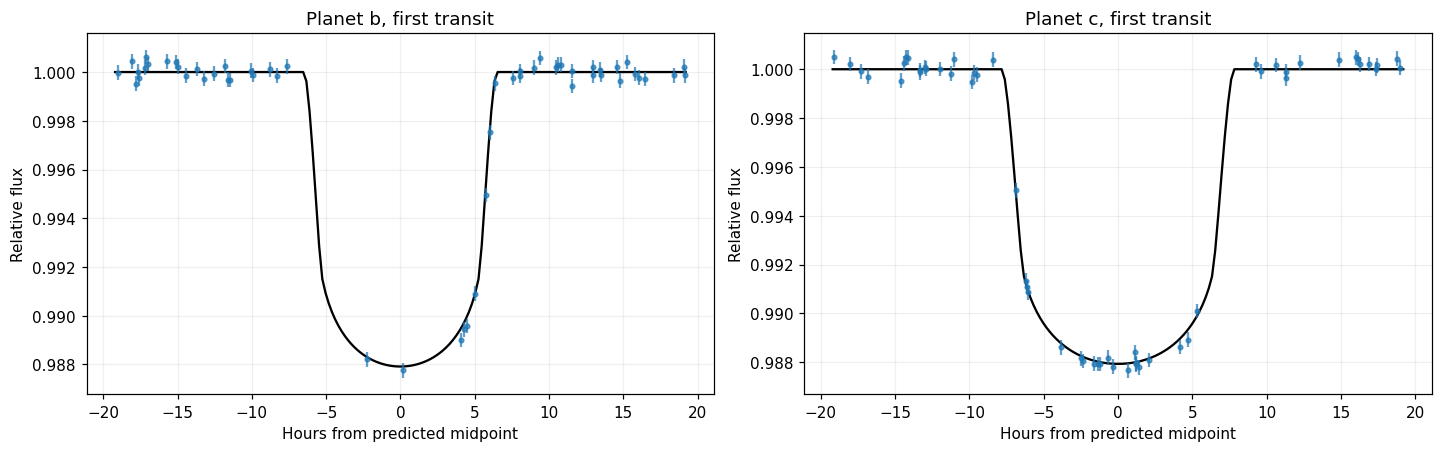

In [6]:
flux_times = np.sort(np.concatenate([
    mid + np.linspace(-.8, .8, 180)
    for event in events.TTV.values() for mid in event.BJD
]))
flux_observations = np.sort(np.concatenate([
    mid + rng.uniform(-.8, .8, 55)
    for event in events.TTV.values() for mid in event.BJD
]))
flux_parameters = {'limb_dark': 'quadratic', 'coefficients': [.4, .2],
                   'exposure_time': 120./86400., 'supersample_factor': 5}
flux_model = GetModel(planets, BJD=flux_times, epoch=EPOCH, model='nbody', models={
    'RV': False, 'Transit': {'enabled': True, 'parameters': flux_parameters}})
flux_data = GetModel(planets, BJD=flux_observations, epoch=EPOCH, model='nbody', seed=SEED, models={
    'RV': False, 'Transit': {'enabled': True, 'parameters': flux_parameters, 'noise': {'sigma': .0003}}})

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for ax, (name, event) in zip(axes, events.TTV.items()):
    mid = event.BJD[0]
    chosen_model = np.abs(flux_model.Transit.BJD-mid) < .8
    chosen_data = np.abs(flux_data.Transit.BJD-mid) < .8
    ax.plot((flux_model.Transit.BJD[chosen_model]-mid)*24., flux_model.Transit.model[chosen_model], 'k-')
    ax.errorbar((flux_data.Transit.BJD[chosen_data]-mid)*24., flux_data.Transit.data[chosen_data],
                 yerr=flux_data.Transit.uncertainty[chosen_data], fmt='.', alpha=.7)
    ax.set(title=f'Planet {name}, first transit', xlabel='Hours from predicted midpoint', ylabel='Relative flux')
plt.show()

## 6. Astrometry = one standard stellar model + planetary reflex motion

There is **one shared stellar parallax**, not a parallax per planet. The combined signal is proper motion + parallax displacement + stellar reflex motion from both planets. Planetary physical displacement is converted to angular displacement with that same distance scale.

For an offline, reproducible example we supply Astropy's built-in **Earth** barycentric positions. Replace these with Gaia observer XYZ positions in AU for a mission-specific model. The scan angles below are an illustrative smoothly varying function, not Gaia's actual scanning law. Offsets and uncertainties are mas. The RA parallax convention intentionally matches ExTRA.

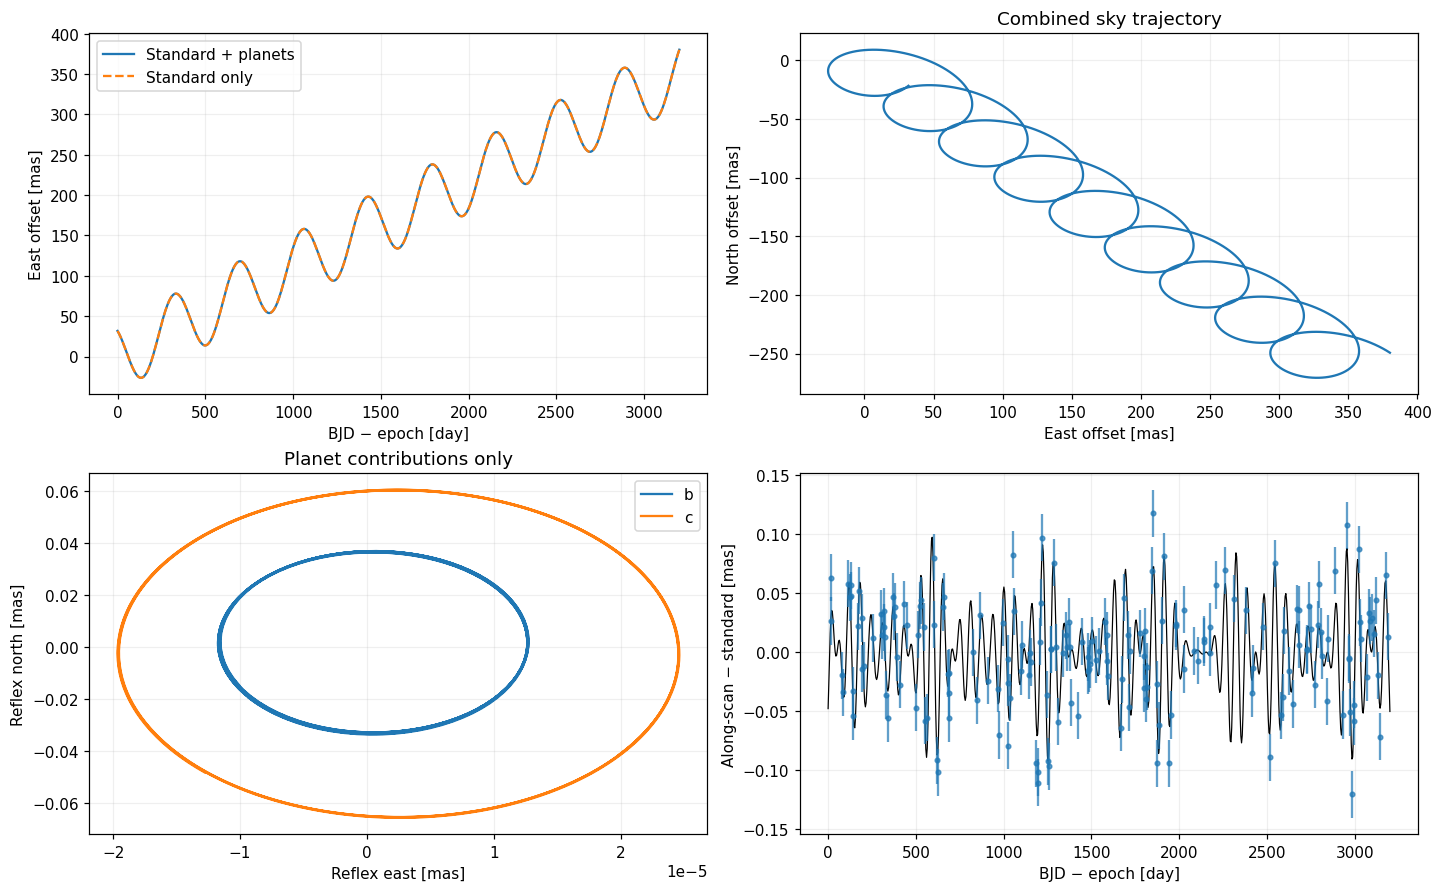

In [7]:
def scan_angles(times):
    return .7 + 2*np.pi*(np.asarray(times)-EPOCH)/63.

astro_times = np.linspace(EPOCH, EPOCH+SPAN, 800)
astro_observations = EPOCH + np.sort(rng.uniform(0., SPAN, 180))

def astro_parameters(times):
    return {'standard': STANDARD.copy(), 'observer': earth_observer(times),
            'scan_angle': scan_angles(times)}

astro_model = GetModel(planets, epoch=EPOCH, model='nbody', models={
    'RV': False, 'Astrometry': {'enabled': True, 'BJD': astro_times,
                              'parameters': astro_parameters(astro_times)}})
astro_data = GetModel(planets, epoch=EPOCH, model='nbody', seed=SEED, models={
    'RV': False, 'Astrometry': {'enabled': True, 'BJD': astro_observations,
                              'parameters': astro_parameters(astro_observations),
                              'noise': {'sigma': .02}}})
standard_model = GetModel({}, epoch=EPOCH, models={
    'RV': False, 'Astrometry': {'enabled': True, 'BJD': astro_times,
                              'parameters': astro_parameters(astro_times)}})
standard_data = GetModel({}, epoch=EPOCH, models={
    'RV': False, 'Astrometry': {'enabled': True, 'BJD': astro_observations,
                              'parameters': astro_parameters(astro_observations)}})

a = astro_model.Astrometry
planet_east = sum(part[:, 0] for part in a.components.values())
planet_north = sum(part[:, 1] for part in a.components.values())
np.testing.assert_allclose(a.East-planet_east, standard_model.Astrometry.East, atol=1e-10)
np.testing.assert_allclose(a.North-planet_north, standard_model.Astrometry.North, atol=1e-10)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
axes[0, 0].plot(astro_times-EPOCH, a.East, label='Standard + planets')
axes[0, 0].plot(astro_times-EPOCH, standard_model.Astrometry.East, '--', label='Standard only')
axes[0, 0].set(ylabel='East offset [mas]', xlabel='BJD − epoch [day]')
axes[0, 0].legend()
axes[0, 1].plot(a.East, a.North)
axes[0, 1].set(xlabel='East offset [mas]', ylabel='North offset [mas]', title='Combined sky trajectory')
for name, part in a.components.items():
    axes[1, 0].plot(part[:, 0], part[:, 1], label=name)
axes[1, 0].set(xlabel='Reflex east [mas]', ylabel='Reflex north [mas]', title='Planet contributions only')
axes[1, 0].legend()
axes[1, 1].plot(astro_times-EPOCH, a.along_scan-standard_model.Astrometry.along_scan, 'k-', lw=.8)
axes[1, 1].errorbar(astro_observations-EPOCH,
                   astro_data.Astrometry.data-standard_data.Astrometry.along_scan,
                   yerr=astro_data.Astrometry.uncertainty, fmt='.', alpha=.7)
axes[1, 1].set(xlabel='BJD − epoch [day]', ylabel='Along-scan − standard [mas]')
plt.show()

## 7. All four outputs in one dictionary, plus independent timestamps

Each observable has its own BJD or start/end grid, physical/profile settings and noise. TTV inherits Transit limb-darkening parameters unless explicitly overridden. Filling the parameters does not implicitly enable a disabled observable.

In [8]:
all_models = GetModelDefaults()
all_models['RV'].update(BJD=rv_data.RV.BJD, noise={'sigma': rv_sigma, 'seed': None})
all_models['Transit'].update(enabled=True, BJD=flux_observations,
                             parameters=flux_parameters, noise={'sigma': .0003, 'seed': None})
all_models['TTV'].update(enabled=True, start=EPOCH, end=EPOCH+SPAN,
                         noise={'sigma': {'b': 60./86400., 'c': 90./86400.}, 'seed': None})
all_models['Astrometry'].update(enabled=True, BJD=astro_observations,
                                parameters=astro_parameters(astro_observations),
                                noise={'sigma': .02, 'seed': None})
combined = GetModel(planets, epoch=EPOCH, model='nbody', models=all_models, seed=SEED)
print('RV / flux / astrometric samples:', len(combined.RV.BJD), len(combined.Transit.BJD),
      len(combined.Astrometry.BJD))
print('Transit counts:', {name: len(table.BJD) for name, table in combined.TTV.items()})

RV / flux / astrometric samples: 159 825 180
Transit counts: {'b': 10, 'c': 5}


## 8. Density geometry, t0 phase convention, exposure integration and empty systems

Additional API checks: common stellar density versus physically derived axes; Keplerian phase supplied as nominal conjunction t0 instead of M0; long-exposure smoothing; and the single-star baseline. Nominal t0 uses the existing Keplerian convention, not an assertion that every conjunction crosses the stellar disk.

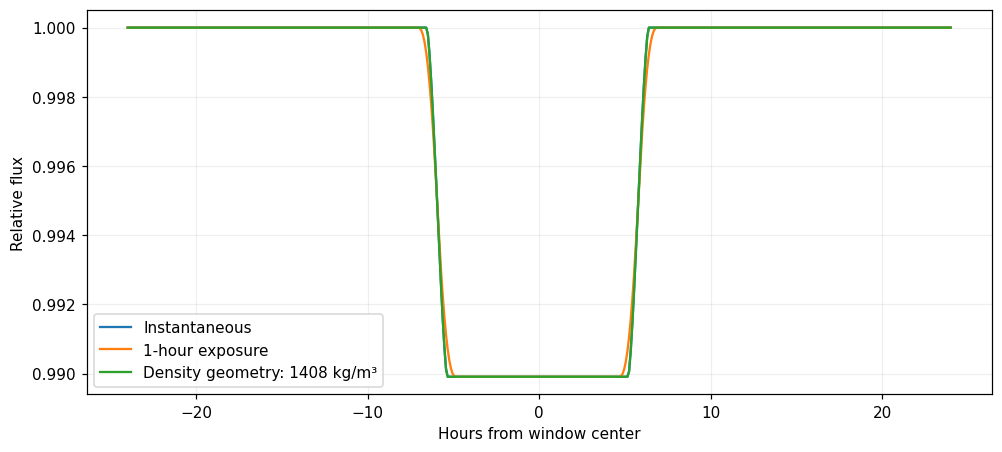

t0/M0 equivalence and empty-system checks passed.


In [9]:
near_first = events.TTV['b'].BJD[0] + np.linspace(-1., 1., 500)
short_exposure = GetModel(planets, BJD=near_first, epoch=EPOCH, models={'RV': False, 'Transit': True})
long_exposure = GetModel(planets, BJD=near_first, epoch=EPOCH, models={
    'RV': False, 'Transit': {'enabled': True, 'parameters': {
        'exposure_time': 1./24., 'supersample_factor': 31}}})
density_model = GetModel(planets, BJD=near_first, epoch=EPOCH, rho_star=1408.,
                         models={'RV': False, 'Transit': True})
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
for result, label in [(short_exposure, 'Instantaneous'), (long_exposure, '1-hour exposure'),
                       (density_model, 'Density geometry: 1408 kg/m³')]:
    ax.plot((result.Transit.BJD-near_first.mean())*24., result.Transit.model, label=label)
ax.set(xlabel='Hours from window center', ylabel='Relative flux')
ax.legend()
plt.show()

nominal_t0 = []
for p in planets.values():
    true_anomaly = np.deg2rad(90.-p['omega'])
    eccentric_anomaly = 2*np.arctan2(np.sqrt(1-p['e'])*np.sin(true_anomaly/2),
                                    np.sqrt(1+p['e'])*np.cos(true_anomaly/2))
    conjunction_mean = np.rad2deg(eccentric_anomaly-p['e']*np.sin(eccentric_anomaly))
    nominal_t0.append(EPOCH + ((conjunction_mean-p['M0']) % 360.)/360.*p['P'])
phase_model = GetModel(planets, BJD=dense_times, epoch=EPOCH, phase='t0', t0=nominal_t0)
np.testing.assert_allclose(phase_model.RV.model, kepler.RV.model, atol=1e-7)
empty = GetModel({}, start=EPOCH, end=EPOCH+1, models={'Transit': True, 'TTV': True})
np.testing.assert_array_equal(empty.RV.model, 0.)
np.testing.assert_array_equal(empty.Transit.model, 1.)
assert empty.TTV == {}
print('t0/M0 equivalence and empty-system checks passed.')

## 9. Export every simulated observable

The saved CSV files keep noiseless predictions and noisy measurements separate. TTV uncertainty is exported in days and depths are fractional flux losses. No session fixture is overwritten.

In [10]:
write_csv(OUTPUT/'synthetic_RV.csv', {
    'BJD': combined.RV.BJD, 'model_m_s': combined.RV.model,
    'data_m_s': combined.RV.data, 'sigma_m_s': combined.RV.uncertainty,
})
write_csv(OUTPUT/'synthetic_transit.csv', {
    'BJD': combined.Transit.BJD, 'model_flux': combined.Transit.model,
    'data_flux': combined.Transit.data, 'sigma_flux': combined.Transit.uncertainty,
})
write_csv(OUTPUT/'synthetic_astrometry.csv', {
    'BJD': combined.Astrometry.BJD, 'east_mas': combined.Astrometry.East,
    'north_mas': combined.Astrometry.North,
    'along_scan_model_mas': combined.Astrometry.along_scan,
    'along_scan_data_mas': combined.Astrometry.data,
    'sigma_mas': combined.Astrometry.uncertainty,
})
for name, table in combined.TTV.items():
    write_csv(OUTPUT/f'synthetic_TTV_{name}.csv', {
        'N_transit': table.N_transit, 'BJD_model': table.BJD, 'BJD_data': table.data,
        'sigma_day': table.uncertainty, 'BJD_minus_mean': table.BJD_minus_mean,
        'O_C_day': table.O_C, 'depth': table.Depth, 'duration_day': table.Duration,
        'T1': table.T1, 'T2': table.T2, 'T3': table.T3, 'T4': table.T4,
    })
print('\n'.join(str(path.name) for path in sorted(OUTPUT.glob('*.csv'))))

synthetic_RV.csv
synthetic_TTV_b.csv
synthetic_TTV_c.csv
synthetic_astrometry.csv
synthetic_transit.csv


## 10. Load the included `.ses` and generate models/data from its fit object

`examples/sessions/GetModel_giant_planets.ses` contains a native LM fit to a **separate Keplerian synthetic RV dataset**, an instrumental offset, fixed transit radii/inclinations, and real retained MCMC and NS arrays. The adjacent `.vels` file is included. The fit has K/P/M0 free for each planet and an instrumental offset; e/omega/inclination/node/mass/radii are fixed tutorial assumptions.

Change `SESSION_PATH` to your own compatible file. Use only session files you trust: `.ses` is a serialized Python object. The adapter reads the fit's parameters without calling fitting/preparation methods or changing its sampler mapping. Instrument offsets and GP noise are not planetary model components. Deterministic RV trends are included.

Astrometric `ast_*` fields in Exo-Striker can be **corrections** to a catalog solution. Therefore supply the absolute best-fit standard solution explicitly rather than treating these corrections as RA/Dec/parallax.

planet,K,P,e,omega,M0,inclination,node,radius_ratio
str8,float64,float64,float64,float64,float64,float64,float64,float64
planet_1,29.608542227894702,320.02936367802016,0.08,40.0,20.528940346236382,89.98,0.0,0.10045
planet_2,25.56831177894374,679.5510311102269,0.12,110.0,299.9782594046538,89.98,0.0,0.10045


Session: GetModel synthetic two-giant-planet tutorial
Free columns: ['RV off$_1$ [m/s]', 'K$_b$ [m/s]', 'P$_b$ [d]', 'MA$_b$ [deg]', 'K$_c$ [m/s]', 'P$_c$ [d]', 'MA$_c$ [deg]']
Physical model has no instrument offset; fitted offset: 11.986150702897929 m/s


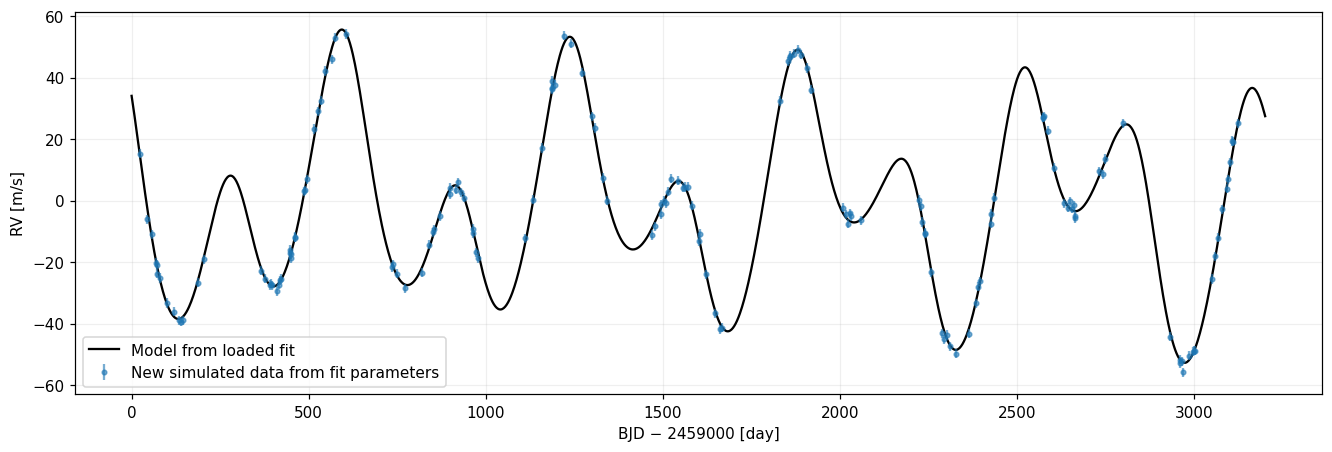

In [11]:
SESSION_PATH = ROOT / 'examples' / 'sessions' / 'GetModel_giant_planets.ses'
fit = load_demo_session(SESSION_PATH)
adapter = SessionModelAdapter(fit)
fit_planets, fit_options, rv_trends, sky_corrections = adapter.inputs()
display(Table(rows=[{'planet': name, **parameters} for name, parameters in fit_planets.items()]))
print('Session:', fit.name)
print('Free columns:', list(fit.e_for_mcmc))
print('Physical model has no instrument offset; fitted offset:', fit.rvoff[0], 'm/s')

fit_model = GetModelFromSession(fit, BJD=dense_times)
fit_simulation = GetModelFromSession(fit, BJD=rv_data.RV.BJD, seed=13,
                                    models={'RV': {'noise': {'sigma': 1.5}}})
manual_model = GetModel(fit_planets, BJD=dense_times, **fit_options)
np.testing.assert_allclose(fit_model.RV.model, manual_model.RV.model, atol=1e-12)

fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
ax.plot(dense_times-EPOCH, fit_model.RV.model, 'k-', label='Model from loaded fit')
ax.errorbar(fit_simulation.RV.BJD-EPOCH, fit_simulation.RV.data,
             yerr=fit_simulation.RV.uncertainty, fmt='.', alpha=.6, label='New simulated data from fit parameters')
ax.set(xlabel=f'BJD − {EPOCH:.0f} [day]', ylabel='RV [m/s]')
ax.legend()
plt.show()

## 11. Retained posterior rows: MCMC versus weighted nested sampling

No sampler is launched by default. MCMC rows retain repeated states and have equal empirical weights. NS uses **raw `samples_ns` with aligned `logwt`**; it never pairs resampled/sorted rows with unrelated raw weights. The provided NS run uses known-period/phase tutorial prior boxes; MCMC used wider initialization boxes. These demonstrations are conditional on their priors and fixed parameters, and their evidences must not be compared as if the priors were identical.

The printed weight ESS is a concentration diagnostic, **not autocorrelation-adjusted MCMC ESS**. `max_samples` below explicitly approximates a larger posterior by resampling its mass with replacement. Set it to None to propagate every retained row, especially for robust tail estimates.

In [12]:
mcmc_posterior = PosteriorSamplesFromSession(fit, 'mcmc')
ns_posterior = PosteriorSamplesFromSession(fit, 'ns')
for posterior in (mcmc_posterior, ns_posterior):
    print(posterior.source, 'rows/columns:', posterior.values.shape,
          'weight ESS:', 1./np.sum(posterior.weights**2))
print('Best fitted lnL:', fit.loglik, '; maximum NS raw lnL:', np.max(fit.ns_sampler.logl_ns))
N_DRAWS = 512  # Increase substantially and check tail ESS for scientific 3σ inference.

mcmc rows/columns: (16800, 7) weight ESS: 16799.999999999996
ns rows/columns: (3803, 7) weight ESS: 735.7222326246462
Best fitted lnL: -334.76796607065916 ; maximum NS raw lnL: -335.09338422717906


## 12. Grey 1/2/3σ posterior bands for all observables

These are **pointwise equal-tail credible bands** containing approximately 68.27%, 95.45% and 99.73% posterior model probability at each timestamp. They are not simultaneous confidence regions, and they do not include future measurement noise. The black curve is the model at the saved best fit, not a parameter-wise marginal median.

Simulation noise and timestamp jitter are disabled during propagation. Orbital posterior correlations, weights, h/k/l angle conventions and sparse planet slots are preserved. TTV draws are matched to the reference by orbital cycle; disappearance of a transit lowers its reported coverage instead of shifting all later event numbers.

In [13]:
best_events = GetModelFromSession(fit, start=EPOCH, end=EPOCH+SPAN,
                                  models={'RV': False, 'TTV': True})
posterior_flux_times = np.sort(np.concatenate([
    mid + np.linspace(-1.5, 1.5, 180)
    for table in best_events.TTV.values() for mid in table.BJD[:2]
]))
posterior_rv_times = np.linspace(EPOCH, EPOCH+SPAN, 700)
posterior_astro_times = np.linspace(EPOCH, EPOCH+SPAN, 250)
posterior_models = {
    'RV': {'BJD': posterior_rv_times},
    'Transit': {'enabled': True, 'BJD': posterior_flux_times,
                'parameters': {'limb_dark': 'quadratic', 'coefficients': [.4, .2]}},
    'TTV': {'enabled': True, 'start': EPOCH, 'end': EPOCH+SPAN},
    'Astrometry': {'enabled': True, 'BJD': posterior_astro_times,
                   'parameters': astro_parameters(posterior_astro_times)},
}
posterior = GetPosteriorModels(fit, source='mcmc', models=posterior_models,
                               max_samples=N_DRAWS, seed=SEED)
ns_rv = GetPosteriorModels(fit, source='ns', models={'RV': {'BJD': posterior_rv_times}},
                           max_samples=None)
print('Evaluated MCMC model rows:', len(posterior.indices), '; rejected:', posterior.rejected)
print('NS RV rows:', len(ns_rv.indices), '; retained posterior mass:', ns_rv.retained_mass)

Evaluated MCMC model rows: 512 ; rejected: ()
NS RV rows: 2585 ; retained posterior mass: 1.0


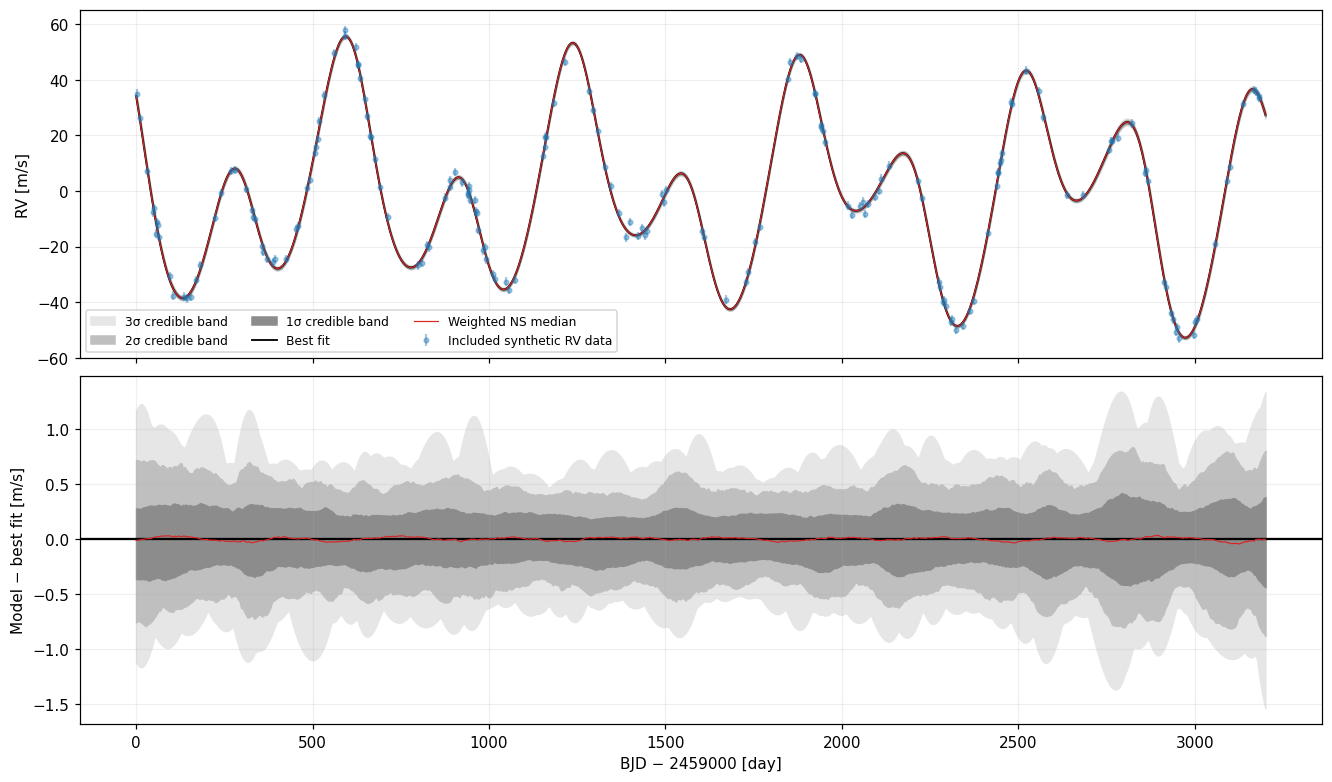

In [14]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 7), layout='constrained')
plot_band(axes[0], posterior.RV)
axes[0].plot(ns_rv.RV.BJD-EPOCH, ns_rv.RV.median, color='tab:red', lw=.8, label='Weighted NS median')
# Original fitted observations, offset-corrected into the physical RV frame.
observed = fit.rv_data_sets[0]
axes[0].errorbar(np.asarray(observed[0])-EPOCH, np.asarray(observed[1])-fit.rvoff[0],
                 yerr=observed[2], fmt='.', alpha=.4, label='Included synthetic RV data')
axes[0].set_ylabel('RV [m/s]')
axes[0].legend(ncol=3, fontsize=8)
for level, shade in ((3, '.90'), (2, '.75'), (1, '.55')):
    lower, upper = posterior.RV.intervals[level]-posterior.RV.best
    axes[1].fill_between(posterior.RV.BJD-EPOCH, lower, upper, color=shade)
axes[1].axhline(0., color='black')
axes[1].plot(ns_rv.RV.BJD-EPOCH, ns_rv.RV.median-posterior.RV.best, color='tab:red', lw=.8)
axes[1].set(xlabel=f'BJD − {EPOCH:.0f} [day]', ylabel='Model − best fit [m/s]')
fig.savefig(OUTPUT/'posterior_RV_bands.png', dpi=160)
plt.show()

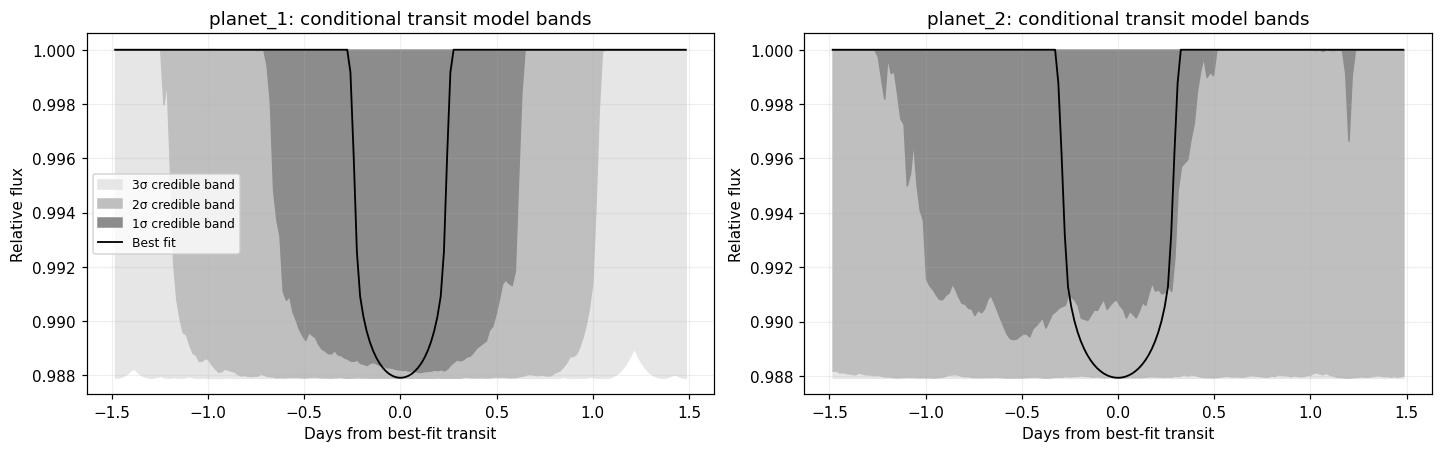

planet_1 minimum transit coverage: 1.0
planet_2 minimum transit coverage: 1.0


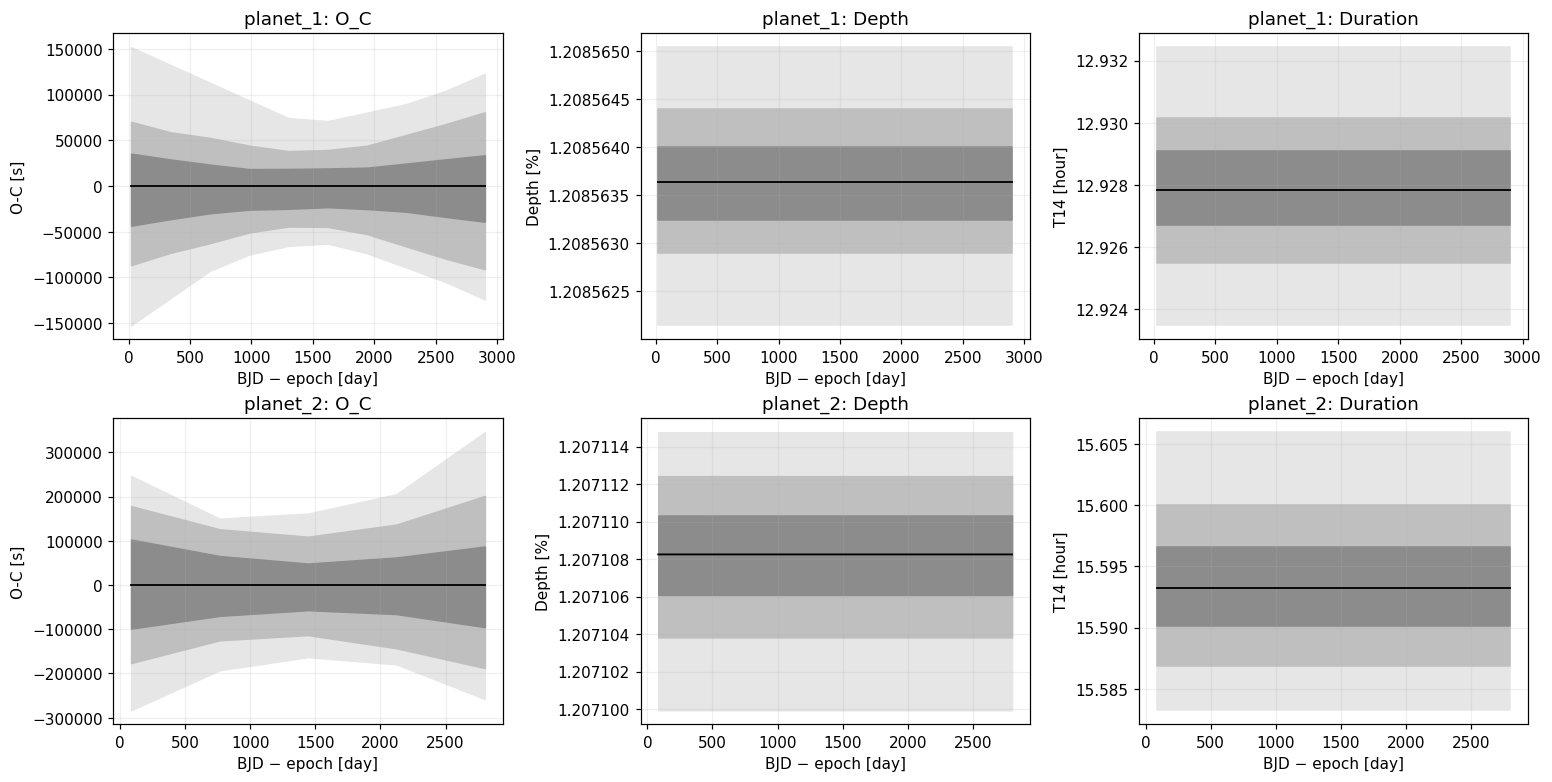

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for ax, (name, event) in zip(axes, best_events.TTV.items()):
    mid = event.BJD[0]
    chosen = np.abs(posterior.Transit.BJD-mid) < 1.5
    band = posterior.Transit
    selected = replace(band, BJD=band.BJD[chosen], best=band.best[chosen], median=band.median[chosen],
                        intervals={level: values[:, chosen] for level, values in band.intervals.items()})
    plot_band(ax, selected, origin=mid)
    ax.set(title=f'{name}: conditional transit model bands', xlabel='Days from best-fit transit', ylabel='Relative flux')
axes[0].legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7), layout='constrained')
for row, (name, fields) in enumerate(posterior.TTV.items()):
    for ax, field, scale, label in zip(axes[row], ['O_C', 'Depth', 'Duration'],
                                     [86400., 100., 24.], ['O-C [s]', 'Depth [%]', 'T14 [hour]']):
        plot_band(ax, fields[field], scale=scale)
        ax.set(title=f'{name}: {field}', xlabel='BJD − epoch [day]', ylabel=label)
    print(name, 'minimum transit coverage:', fields['BJD'].coverage.min())
plt.show()

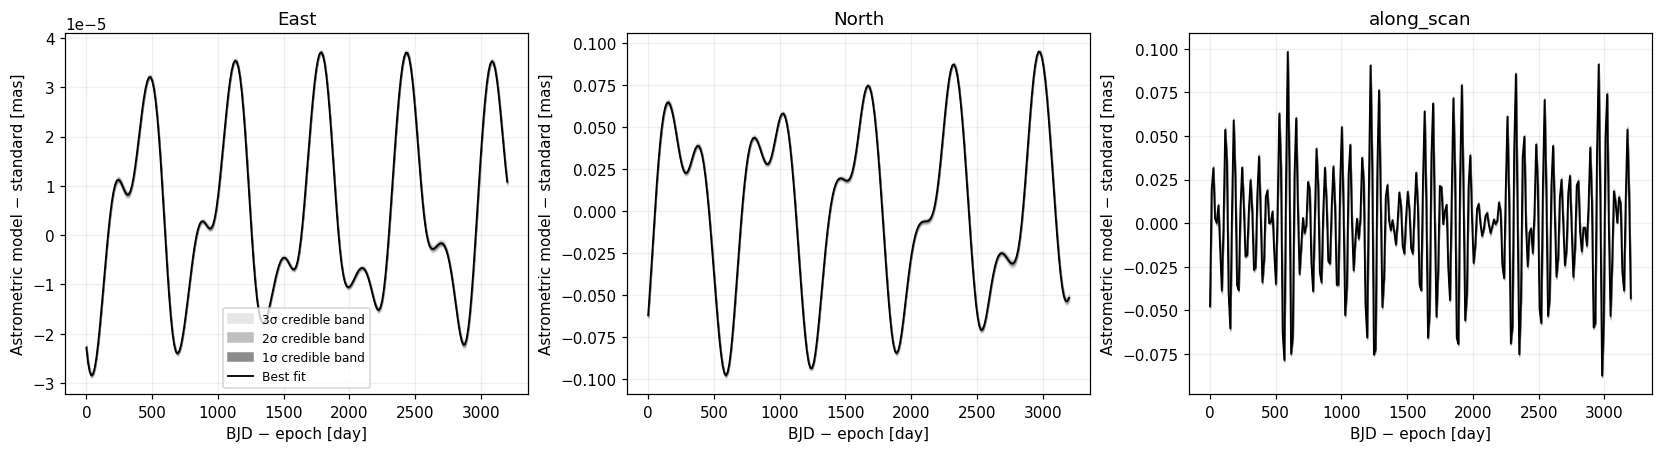

In [16]:
standard_posterior = GetModel({}, epoch=EPOCH, models={
    'RV': False, 'Astrometry': {'enabled': True, 'BJD': posterior_astro_times,
                              'parameters': astro_parameters(posterior_astro_times)}}).Astrometry
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
for ax, field, background in zip(axes, ['East', 'North', 'along_scan'],
                                [standard_posterior.East, standard_posterior.North, standard_posterior.along_scan]):
    band = posterior.Astrometry[field]
    residual_band = replace(band, best=band.best-background, median=band.median-background,
                            intervals={level: values-background for level, values in band.intervals.items()})
    plot_band(ax, residual_band)
    ax.set(title=field, xlabel='BJD − epoch [day]', ylabel='Astrometric model − standard [mas]')
axes[0].legend(fontsize=8)
plt.show()

## 13. Generic reuse with external NS/MCMC parameter arrays

`GetModelEnsemble` accepts any `evaluator(row)` returning the same model structures on fixed BJD grids. Below, two physical columns are extracted from real MCMC rows just to demonstrate a named-dictionary callback. For scientific work, propagate **all relevant correlated parameters**, as `GetPosteriorModels` did above. NS callbacks should receive aligned raw rows **and their weights**.

Invalid draws raise by default. `on_invalid='skip'` explicitly records rejected rows and retained probability mass; rejecting substantial mass changes the posterior and should not be hidden. Event bands need `event_periods` for cycle matching.

In [17]:
chosen_indices = np.random.default_rng(SEED).choice(len(mcmc_posterior.values), size=64, replace=False)
chosen_rows = mcmc_posterior.values[chosen_indices]
physical_columns = []
for row in chosen_rows:
    sampled_planets, _, _, _ = adapter.inputs(row)
    physical_columns.append([sampled_planets['planet_1']['K'], sampled_planets['planet_2']['K']])

def external_sample_model(row):
    draw = deepcopy(fit_planets)
    draw['planet_1']['K'] = row[0]
    draw['planet_2']['K'] = row[1]
    return GetModel(draw, BJD=posterior_rv_times, **fit_options)

external_bands = GetModelEnsemble(external_sample_model, np.asarray(physical_columns),
                                   reference=external_sample_model([fit.K[0], fit.K[1]]))
print('External callback result:', external_bands.RV.draws.shape)

External callback result: (64, 700)


## 14. Optional: fit a new synthetic session or run your own samplers

The included session already contains actual MCMC and NS rows. These switches remain False for a fast, reproducible Run All. A new session is saved under the output directory, not over the bundled fixture. Native sampling uses one process; increase chain length/live points and examine diagnostics before scientific use. Reuse the **same sampling session** and its saved `f_for_mcmc` mapping; do not repack/sort it after sampling.

In [18]:
REBUILD_SESSION = False
RUN_MCMC = False
RUN_NS = False

if REBUILD_SESSION:
    from model_simulation_tools import build_demo_session
    new_fit, new_session_path = build_demo_session(OUTPUT / 'new_session')
    print(new_session_path)
else:
    new_fit = deepcopy(fit)

if RUN_MCMC or RUN_NS:
    from exostriker.lib import RV_mod as rv
    if RUN_MCMC:
        new_fit.mcmc_threads = 1
        new_fit.mcmc_burning_ph = 500
        new_fit.mcmc_ph = 2000
        new_fit.mcmc_save_sampler = True
        rv.run_mcmc(new_fit)
    if RUN_NS:
        new_fit.ns_threads = 1
        new_fit.live_points_fact = 16
        new_fit.ns_save_sampler = True
        rv.run_nestsamp(new_fit)
    print('Reuse GetPosteriorModels(new_fit, source="mcmc" or "ns", ...) above.')
else:
    print('Using the included fitted session and retained posteriors; no new sampler run.')

Using the included fitted session and retained posteriors; no new sampler run.


### Interpretation and limitations

- The confidence-style grey regions are pointwise posterior **credible** bands, conditional on the selected physical model, priors and fixed parameters. MCMC mixing and weighted NS tail mass matter especially for 3σ regions. The notebook's capped MCMC propagation is a fast demonstration; increase `N_DRAWS` or use all rows for tail studies.
- The included posterior was obtained from RV data with e/omega/inclination/node/radii/stellar properties fixed. Transit and astrometric bands therefore reflect only the uncertainty that this RV analysis actually sampled. They do not include unmodeled uncertainty in those fixed quantities.
- MCMC weight ESS does not account for serial correlation. NS weight ESS describes weight concentration. Neither is a convergence certificate.
- Standard astrometry is proper motion + one stellar parallax displacement. Planet components are stellar reflex motion. Earth observer positions and the example scan-angle function are illustrative, not Gaia calibration/scanning predictions.
- The session adapter supports current orbital packing, h/k/l, sparse slots, transit geometry, limb profiles, stellar mass, RV trends and astrometric correction draws. It rejects unsupported free physical blocks instead of silently reinterpreting them. GP realizations, dilution, non-orbital transit trends, mixed subsets, precession and independent fitted per-event shifts need an explicit evaluator.
- Full API/conventions: `docs/MODEL_ONLY.md` and `docs/MODEL_POSTERIORS.md`.